Dataset: Dry Bean Dataset
Total samples: 13611
Original features: 16
Classes: ['SEKER' 'BARBUNYA' 'BOMBAY' 'CALI' 'HOROZ' 'SIRA' 'DERMASON']

Explained Variance Ratio:
PC1: 0.5545 (55.45%)
PC2: 0.2646 (26.46%)
PC3: 0.0804 (8.04%)
PC4: 0.0510 (5.10%)
PC5: 0.0271 (2.71%)
PC6: 0.0114 (1.14%)
PC7: 0.0070 (0.70%)
PC8: 0.0032 (0.32%)
PC9: 0.0005 (0.05%)
PC10: 0.0001 (0.01%)
PC11: 0.0001 (0.01%)
PC12: 0.0000 (0.00%)
PC13: 0.0000 (0.00%)
PC14: 0.0000 (0.00%)
PC15: 0.0000 (0.00%)
PC16: 0.0000 (0.00%)


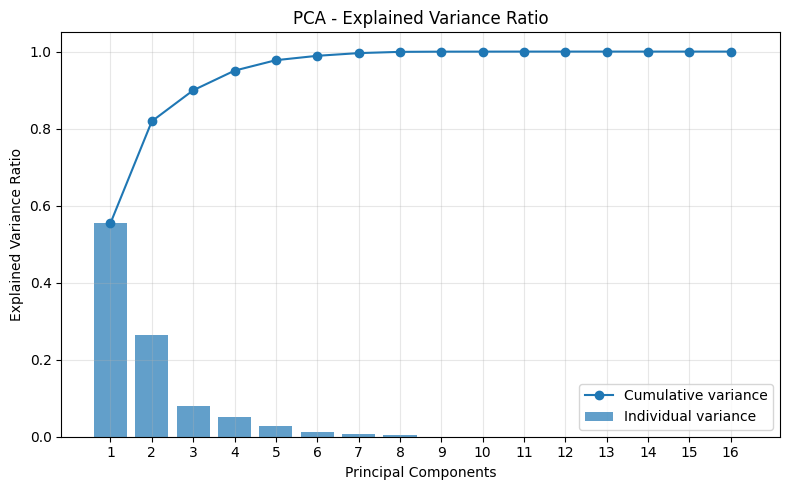


Variance retained by 2 components: 81.92%


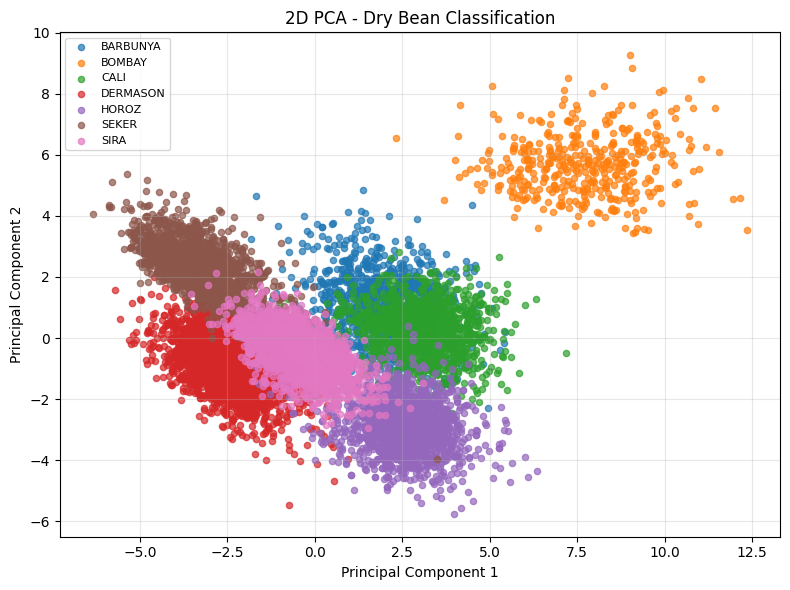


Accuracy Comparison
Original features: 16
Reduced components: 4
Original Data Accuracy: 92.14%
PCA Data Accuracy: 88.73%


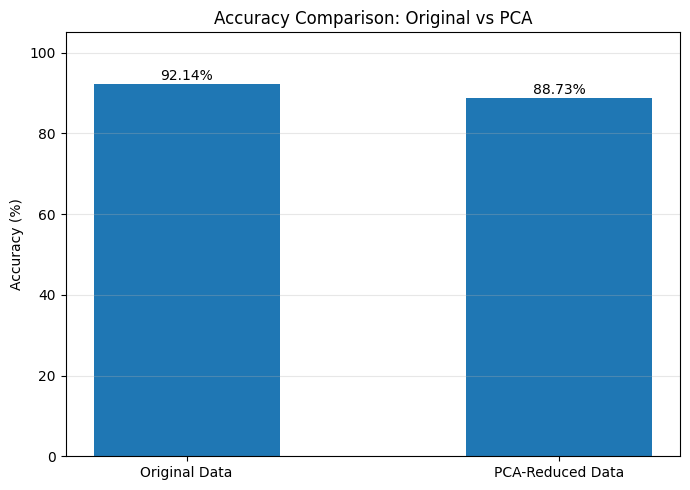


Experiment completed successfully.


In [4]:

# Experiment 10: Dimensionality Reduction using PCA

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# 1. Load Dataset
df = pd.read_csv("Dry Beans Dataset.csv")

print("Dataset: Dry Bean Dataset")
print("Total samples:", df.shape[0])

# 2. Separate Features and Target
X = df.drop(columns=["Class"])
y = df["Class"]

print("Original features:", X.shape[1])
print("Classes:", y.unique())

# 3. Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y
)

# 4. Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. Explained Variance Analysis
pca_full = PCA()
pca_full.fit(X_train_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("\nExplained Variance Ratio:")
for i, value in enumerate(explained_variance, 1):
    print(f"PC{i}: {value:.4f} ({value * 100:.2f}%)")

# OUTPUT 1: Explained Variance Plot
plt.figure(figsize=(8, 5))

plt.bar(
    range(1, len(explained_variance) + 1),
    explained_variance,
    alpha=0.7,
    label="Individual variance"
)

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker="o",
    label="Cumulative variance"
)

plt.xlabel("Principal Components")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA - Explained Variance Ratio")
plt.xticks(range(1, len(explained_variance) + 1))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 6. Reduce Dimensions to 2 Components
pca_2d = PCA(n_components=2)

X_train_2d = pca_2d.fit_transform(X_train_scaled)

print("\nVariance retained by 2 components:",
      f"{sum(pca_2d.explained_variance_ratio_) * 100:.2f}%")

# OUTPUT 2: PCA Scatter Plot
plt.figure(figsize=(8, 6))

for class_name in sorted(y_train.unique()):
    mask = (y_train == class_name).to_numpy()

    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        label=class_name,
        alpha=0.7,
        s=20
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("2D PCA - Dry Bean Classification")
plt.legend(fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Logistic Regression on Original Data
model_original = LogisticRegression(
    max_iter=5000, random_state=42
)

model_original.fit(X_train_scaled, y_train)

pred_original = model_original.predict(X_test_scaled)

accuracy_original = accuracy_score(
    y_test, pred_original
)

# 8. Logistic Regression on PCA-Reduced Data
pca_95 = PCA(n_components=0.95)

X_train_pca = pca_95.fit_transform(X_train_scaled)
X_test_pca = pca_95.transform(X_test_scaled)

model_reduced = LogisticRegression(
    max_iter=5000, random_state=42
)

model_reduced.fit(X_train_pca, y_train)

pred_reduced = model_reduced.predict(X_test_pca)

accuracy_reduced = accuracy_score(
    y_test, pred_reduced
)

# OUTPUT 3: Accuracy Comparison
print("\nAccuracy Comparison")
print("Original features:", X_train_scaled.shape[1])
print("Reduced components:", X_train_pca.shape[1])

print(f"Original Data Accuracy: {accuracy_original * 100:.2f}%")
print(f"PCA Data Accuracy: {accuracy_reduced * 100:.2f}%")

labels = ["Original Data", "PCA-Reduced Data"]

accuracies = [
    accuracy_original * 100,
    accuracy_reduced * 100
]

plt.figure(figsize=(7, 5))

bars = plt.bar(labels, accuracies, width=0.5)

plt.ylabel("Accuracy (%)")
plt.title("Accuracy Comparison: Original vs PCA")
plt.ylim(0, 105)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

print("\nExperiment completed successfully.")
